Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training set: 3000 groups, each with 5 images of size 32x32
Labels: values in [0 1 2 3 4]


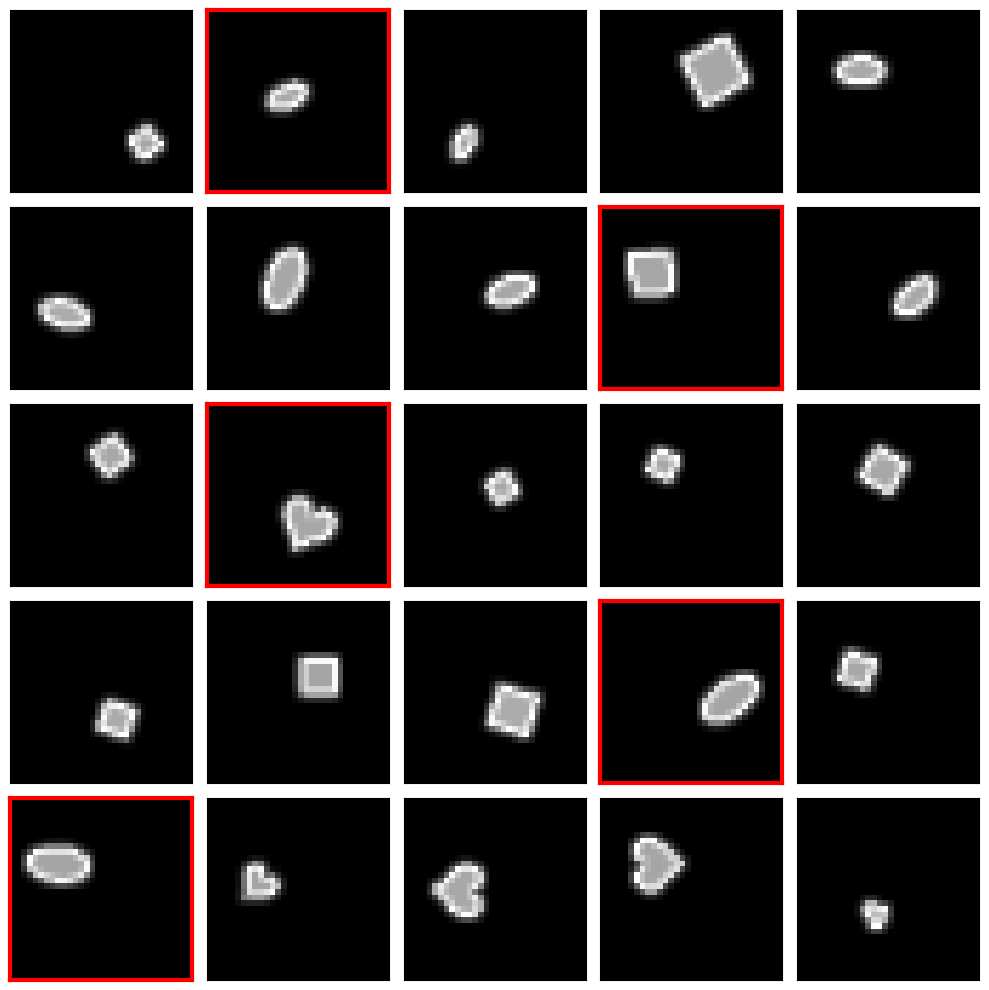

In [11]:
from google.colab import drive
drive.mount('/content/drive')

# STEP 1

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

x = np.load('/content/drive/MyDrive/comp551_a3_data/x_train.npy')
y = np.load('/content/drive/MyDrive/comp551_a3_data/y_train.npy')

print(f'Training set: {x.shape[0]} groups, each with {x.shape[1]} images of size {x.shape[2]}x{x.shape[3]}')
print(f'Labels: values in {np.unique(y)}')


def plot_groups(x, y, num_groups=5):
    fig, axes = plt.subplots(num_groups, 5, figsize=(10, 2 * num_groups))
    for i in range(num_groups):
        for j in range(5):
            axes[i, j].imshow(x[i, j], cmap='gray')
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            if j == y[i]:
                for spine in axes[i, j].spines.values():
                    spine.set_edgecolor('red')
                    spine.set_linewidth(3)
    plt.tight_layout()
    plt.show()


plot_groups(x, y, num_groups=5)



In [12]:
# STEP 2

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import warnings

warnings.filterwarnings('ignore')

features = x.reshape(x.shape[0], -1)
labels = y

x_train, x_val, y_train, y_val = train_test_split(
    features, labels, test_size=0.33, random_state=42
)

clf = LogisticRegression(max_iter=1000)
clf.fit(x_train, y_train)

predictions = clf.predict(x_val)
accuracy = accuracy_score(y_val, predictions)
print(f'The validation accuracy of the baseline model is {accuracy * 100:.2f}%')






The validation accuracy of the baseline model is 19.09%


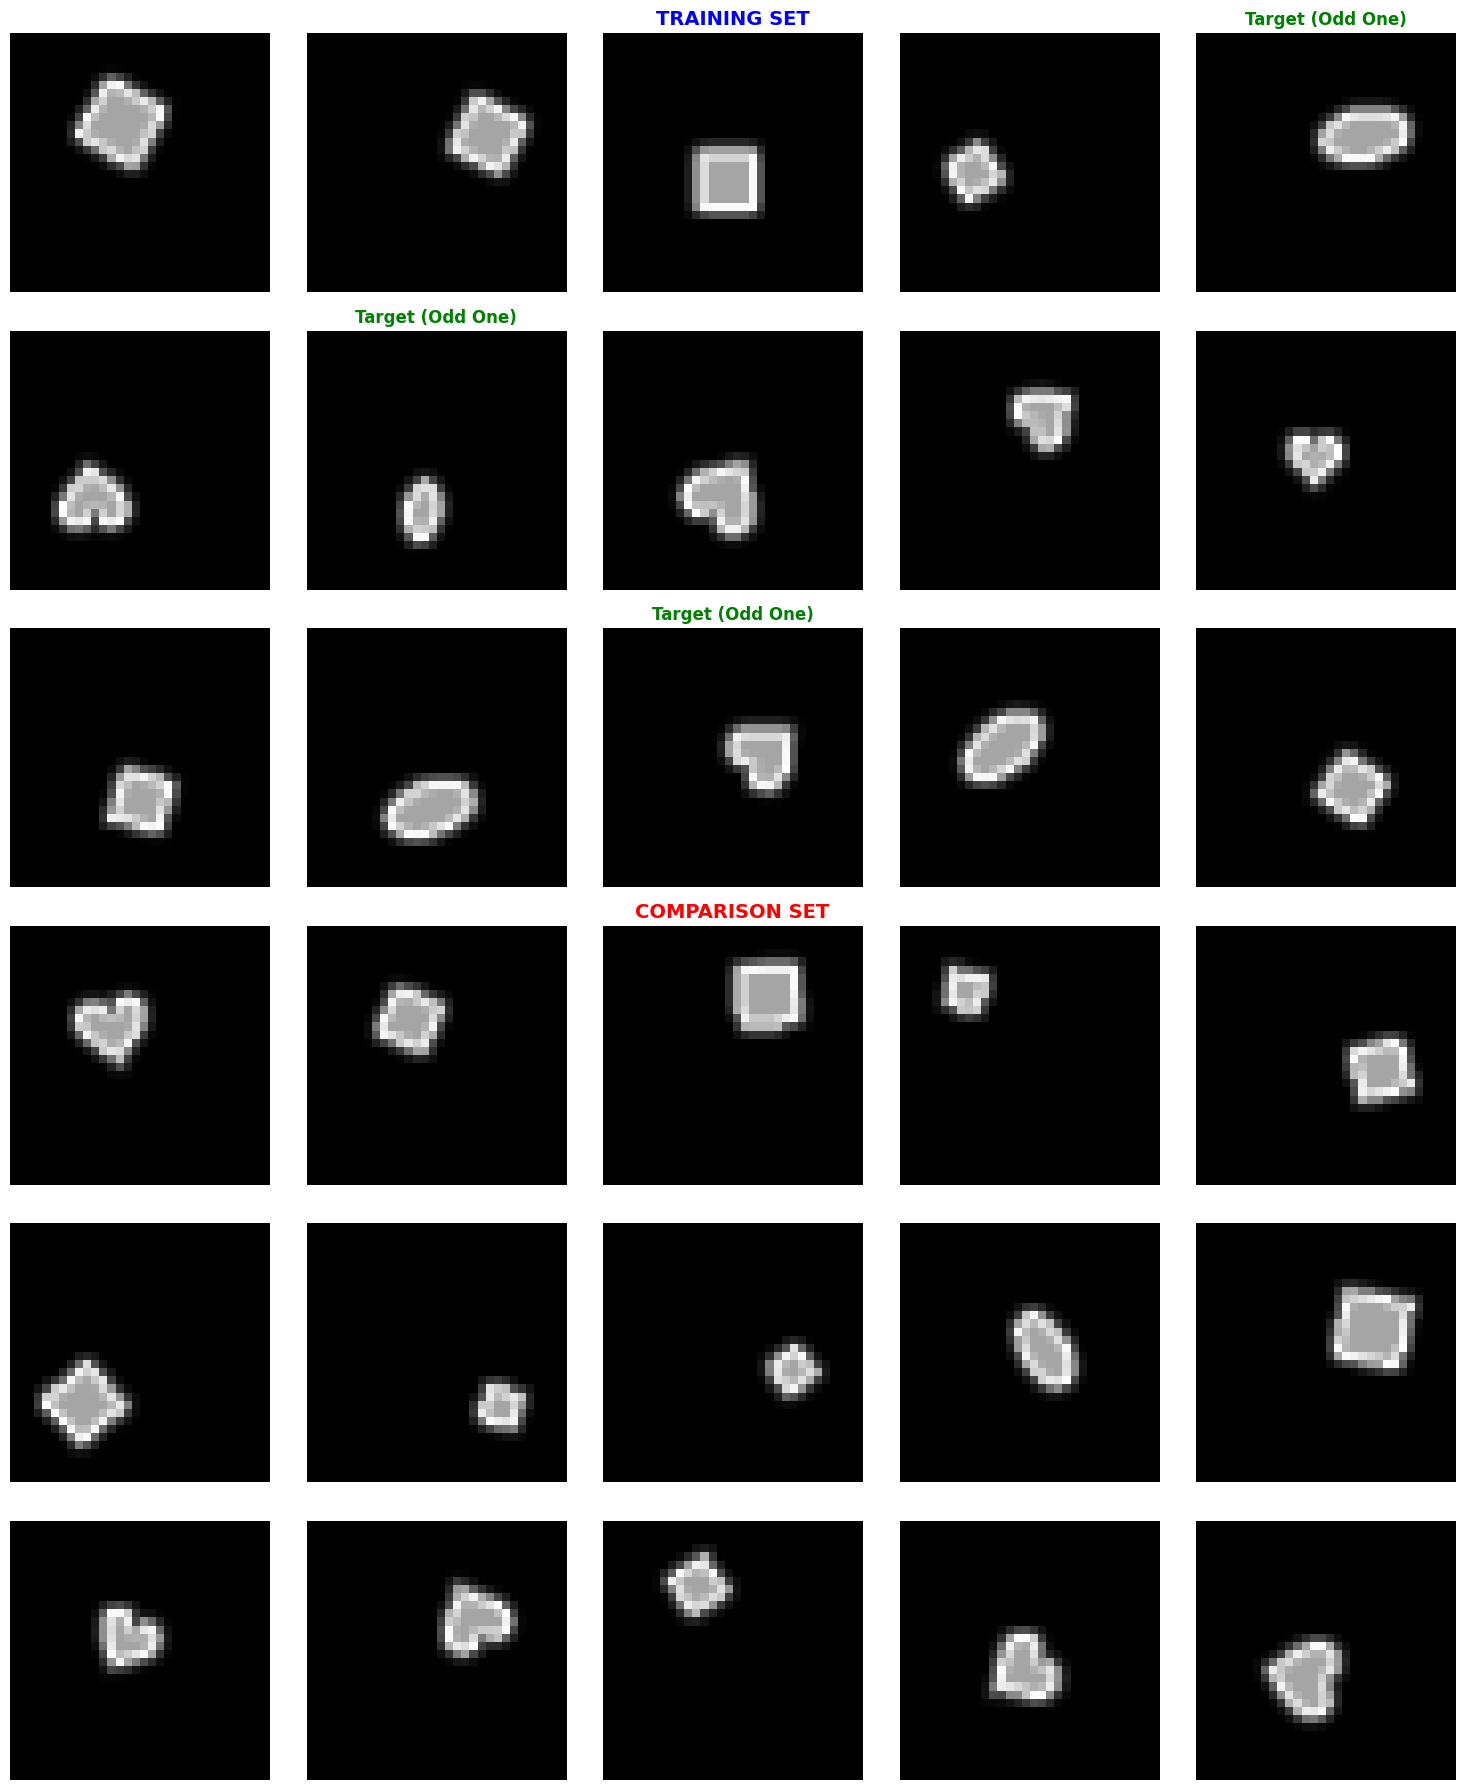

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

def plot_ood_comparison(x_train, y_train, x_test, num_samples=3):
    fig, axes = plt.subplots(num_samples * 2, 5, figsize=(15, 3 * num_samples * 2))

    train_indices = np.random.choice(len(x_train), num_samples, replace=False)
    for i, idx in enumerate(train_indices):
        group = x_train[idx]
        label = int(y_train[idx])

        for j in range(5):
            ax = axes[i, j]
            img = group[j]
            ax.imshow(img, cmap='gray', vmin=0, vmax=1)
            ax.axis('off')

            if j == label:
                ax.set_title("Target (Odd One)", color='green', fontweight='bold')
            elif j == 2 and i == 0:
                ax.set_title("TRAINING SET", color='blue', fontweight='bold', fontsize=14)

    test_indices = np.random.choice(len(x_test), num_samples, replace=False)
    for i, idx in enumerate(test_indices):
        group = x_test[idx]

        for j in range(5):
            ax = axes[i + num_samples, j]
            img = group[j]
            ax.imshow(img, cmap='gray', vmin=0, vmax=1)
            ax.axis('off')

            if j == 2 and i == 0:
                ax.set_title("COMPARISON SET", color='red', fontweight='bold', fontsize=14)

    plt.tight_layout()
    plt.show()

x_train_img, x_val_img, y_train_img, y_val_img = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

x_train_img = x_train_img.astype(np.float32) / 255.0
x_val_img = x_val_img.astype(np.float32) / 255.0

plot_ood_comparison(x_train_img, y_train_img, x_val_img)

In [14]:
# STEP 3: Model

seed = 42
batch_size = 64
data_path = '/content/drive/MyDrive/comp551_a3_data/'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(seed)
np.random.seed(seed)

#to load and normalize all data splits
x_train_np = np.load(data_path + 'x_train.npy').astype(np.float32) / 255.0
y_train_np = np.load(data_path + 'y_train.npy')
x_test_np = np.load(data_path + 'x_test.npy').astype(np.float32) / 255.0
y_test_np  = np.load(data_path + 'y_test.npy')

# convert from numpy -> torch
X_train_full = torch.tensor(x_train_np)
Y_train_full = torch.tensor(y_train_np, dtype=torch.long)
X_test = torch.tensor(x_test_np)
Y_test = torch.tensor(y_test_np,  dtype=torch.long)

class OddOneOutData(Dataset):
    def __init__(self, x, y):
        self.x = x
        self.y = y

    def __len__(self):
      return len(self.x)

    def __getitem__(self, idx):
      return self.x[idx], self.y[idx]

#spliting data 80/20 train/val split
n_total = len(X_train_full)
n_vl = int(0.2 * n_total) #600 items
n_tr = n_total - n_vl #2400 items

dataset = OddOneOutData(X_train_full, Y_train_full)
tr_subset, val_subset = random_split(dataset, [n_tr, n_vl])

tr_loader = DataLoader(tr_subset, batch_size=batch_size, shuffle=True, drop_last=True) ###
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)
test_dataset = OddOneOutData(X_test[:len(Y_test)], Y_test)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

class Encoder(nn.Module):
  def __init__(self, feature_dim=42):
    super(Encoder, self).__init__()

    self.net = nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(16, 28, kernel_size=3, padding=1),
        nn.BatchNorm2d(28),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(28, feature_dim, kernel_size=3, padding=1),
        nn.BatchNorm2d(feature_dim),
        nn.ReLU(),
        nn.AdaptiveAvgPool2d(1),
        nn.Flatten()
    )

  def forward(self, x):
    return self.net(x)

class SiameseNetwork(nn.Module): # inherit nn.Module class then override forward(self, x)
    def __init__(self, feature_dim=42):
        super(SiameseNetwork, self).__init__()
        self.encoder = Encoder()
        self.feature_dim = feature_dim

        # learned projection to transform embeddings into queries for self-attention
        self.attention_proj = nn.Linear(feature_dim, feature_dim, bias=False)

        self.outlier_classifier = nn.Sequential(
            nn.Linear(feature_dim * 3, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        B, N, H, W = x.shape
        x_reshaped = x.reshape(-1, 1, H, W)

        features = self.encoder(x_reshaped) # flatten batch to process all images together in cnn
        features = features.view(B, N, -1) # reshape and l2 normalization
        features = F.normalize(features, p=2, dim=-1)

        queries = self.attention_proj(features)
        sim_m = torch.bmm(queries, features.transpose(1, 2)) / (self.feature_dim ** 0.5) #scale for stability

        mask = torch.eye(N, device=features.device).unsqueeze(0).bool() # mask to prevent the Softmax from comparing relationship of image to itself
        sim_m = sim_m.masked_fill(mask, float('-inf'))

        selection_weights = F.softmax(sim_m, dim=-1)
        context = torch.bmm(selection_weights, features)
        diff = features - context

        combined = torch.cat([features, context, diff], dim=-1)
        outlier_logits = self.outlier_classifier(combined.view(B * N, -1)).view(B, N)
        return outlier_logits


In [15]:
import torchvision.transforms as transforms
import copy

def aug(x, y, is_training=True):
    batch_size = x.shape[0]
    x_aug = x.clone()
    y_aug = torch.zeros_like(y)

    for i in range(batch_size):
        perm = torch.randperm(5) # shuffle to prevent assumption that outlier is often at a specific index
        for j in range(5):
            img = x[i, perm[j]].clone()

            if is_training: # augment each of the 5 images differently so the model can't cheat
                k = torch.randint(0, 4, (1,)).item()
                img = torch.rot90(img, k, [-2, -1]) # eg. random 90 deg rotation

                if torch.rand(1).item() > 0.5: # eg. random h-flip
                    img = img.flip(-1)
                if torch.rand(1).item() > 0.5: # eg. random v-flip
                    img = img.flip(-2)

                if torch.rand(1).item() > 0.5: # eg. move shape a few pixel to make translation-invariant
                    dx = torch.randint(-3, 4, (1,)).item()
                    dy = torch.randint(-3, 4, (1,)).item()
                    img = torch.roll(img, shifts=(dy, dx), dims=(-2, -1))

            img = torch.clamp(img, 0.0, 1.0) # [0,1]
            x_aug[i, j] = img

        y_aug[i] = (perm == y[i]).nonzero(as_tuple=True)[0][0]

    return x_aug, y_aug

model = SiameseNetwork().to(device)
optimizer = optim.AdamW(model.parameters(), lr=0.002, weight_decay=1e-3)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1) ###
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=40, T_mult=1, eta_min=1e-5)

best_val_acc = 0.0
best_model_weights = None

EPOCHS = 200
for epoch in range(EPOCHS):
  model.train()
  total_loss = 0
  for images, labels in tr_loader:
    images, labels = aug(images, labels)
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    total_loss += loss.item()

  scheduler.step()
  model.eval()
  correct = 0
  with torch.no_grad():
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      preds = outputs.argmax(dim=1)
      correct += (preds == labels).sum().item()

  train_loss = total_loss / len(tr_loader)
  val_acc = 100 * correct / n_vl

  if val_acc > best_val_acc:
    best_val_acc = val_acc
    best_model_weights = copy.deepcopy(model.state_dict())

  if (epoch + 1) % 5 == 0 or epoch == 0:
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Loss: {train_loss:.4f} | Val Acc: {val_acc:.4f}%")

model.load_state_dict(best_model_weights)

Epoch 01/200 | Loss: 1.6081 | Val Acc: 24.6667%
Epoch 05/200 | Loss: 1.5332 | Val Acc: 28.6667%
Epoch 10/200 | Loss: 1.3396 | Val Acc: 37.1667%
Epoch 15/200 | Loss: 1.1281 | Val Acc: 59.1667%
Epoch 20/200 | Loss: 1.1003 | Val Acc: 62.5000%
Epoch 25/200 | Loss: 1.0772 | Val Acc: 66.0000%
Epoch 30/200 | Loss: 1.0635 | Val Acc: 67.0000%
Epoch 35/200 | Loss: 1.0522 | Val Acc: 68.3333%
Epoch 40/200 | Loss: 1.0539 | Val Acc: 68.0000%
Epoch 45/200 | Loss: 1.0162 | Val Acc: 75.0000%
Epoch 50/200 | Loss: 0.8468 | Val Acc: 83.1667%
Epoch 55/200 | Loss: 0.7798 | Val Acc: 83.0000%
Epoch 60/200 | Loss: 0.7493 | Val Acc: 83.6667%
Epoch 65/200 | Loss: 0.7364 | Val Acc: 83.8333%
Epoch 70/200 | Loss: 0.7261 | Val Acc: 83.6667%
Epoch 75/200 | Loss: 0.7134 | Val Acc: 84.5000%
Epoch 80/200 | Loss: 0.7131 | Val Acc: 84.1667%
Epoch 85/200 | Loss: 0.7444 | Val Acc: 83.0000%
Epoch 90/200 | Loss: 0.7464 | Val Acc: 77.6667%
Epoch 95/200 | Loss: 0.7215 | Val Acc: 83.5000%
Epoch 100/200 | Loss: 0.7168 | Val Acc: 

<All keys matched successfully>

In [16]:

# ============================================================
# REQUIRED: Print the number of trainable parameters in your model.
# Replace `model` with the name of your PyTorch model.
# This cell MUST appear with its output in your submitted notebook.
# ============================================================

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total trainable parameters: {total_params:,}')
assert total_params <= 25_000, f'Model too large! {total_params:,} > 25,000'



Total trainable parameters: 24,975


In [17]:
# ============================================================
# REQUIRED: Print your model's accuracy on the public test half.
# This number MUST match your public leaderboard score on Kaggle.
# Replace the code below with your own model's predictions.
# ============================================================
X_test_public = X_test[:len(Y_test)]

test_dataset = OddOneOutData(X_test_public, Y_test)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

def test_with_tta(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits_orig = model(images)
            logits_hflip = model(torch.flip(images, dims=[-1]))
            logits_vflip = model(torch.flip(images, dims=[-2]))
            avg_logits = (logits_orig + logits_hflip + logits_vflip) / 3.0
            preds = avg_logits.argmax(dim=1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total
    print(f"Public Test Accuracy: {accuracy:.2f}%")

test_with_tta(model, test_loader)

Public Test Accuracy: 69.10%


Epoch 001/200 | Train Loss: 1.6093 | Val Loss: 1.6092 | Val Acc: 23.67%
Epoch 005/200 | Train Loss: 1.5920 | Val Loss: 1.5839 | Val Acc: 33.17%
Epoch 010/200 | Train Loss: 1.4247 | Val Loss: 1.3651 | Val Acc: 50.50%
Epoch 015/200 | Train Loss: 1.2013 | Val Loss: 1.4338 | Val Acc: 47.67%
Epoch 020/200 | Train Loss: 1.0625 | Val Loss: 1.0087 | Val Acc: 77.00%
Epoch 025/200 | Train Loss: 1.0378 | Val Loss: 1.1420 | Val Acc: 68.17%
Epoch 030/200 | Train Loss: 1.0013 | Val Loss: 1.0119 | Val Acc: 80.17%
Epoch 035/200 | Train Loss: 0.9687 | Val Loss: 1.0562 | Val Acc: 76.00%
Epoch 040/200 | Train Loss: 0.9423 | Val Loss: 0.9091 | Val Acc: 82.83%
Epoch 045/200 | Train Loss: 0.9012 | Val Loss: 0.8753 | Val Acc: 84.33%
Epoch 050/200 | Train Loss: 0.8892 | Val Loss: 0.9728 | Val Acc: 82.17%
Epoch 055/200 | Train Loss: 0.8697 | Val Loss: 0.9459 | Val Acc: 81.50%
Epoch 060/200 | Train Loss: 0.8476 | Val Loss: 0.9246 | Val Acc: 82.17%
Epoch 065/200 | Train Loss: 0.8519 | Val Loss: 0.8184 | Val Acc:

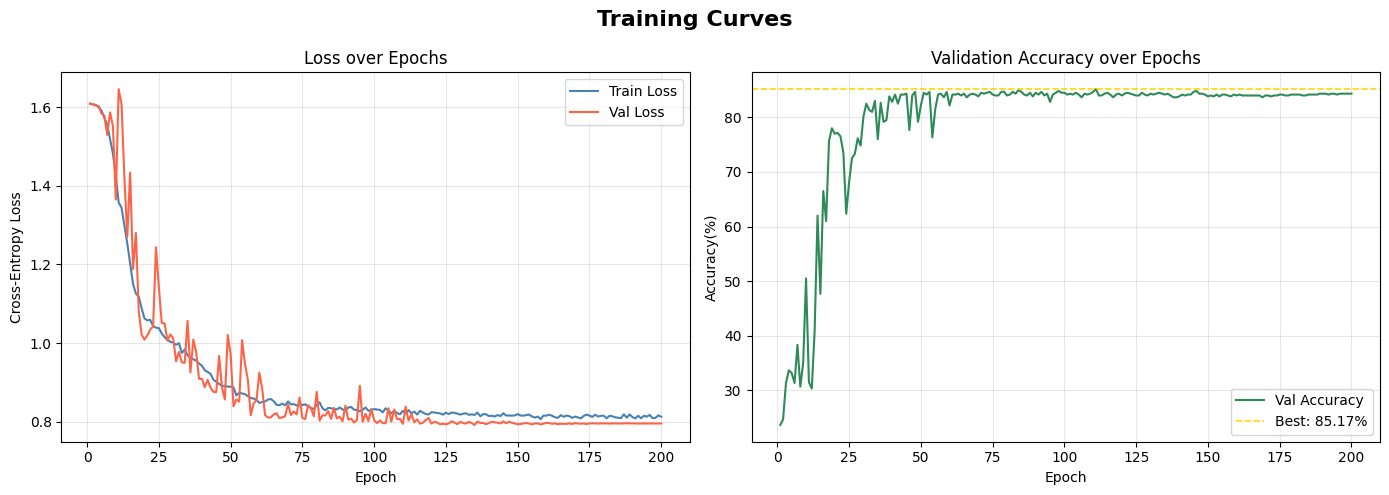

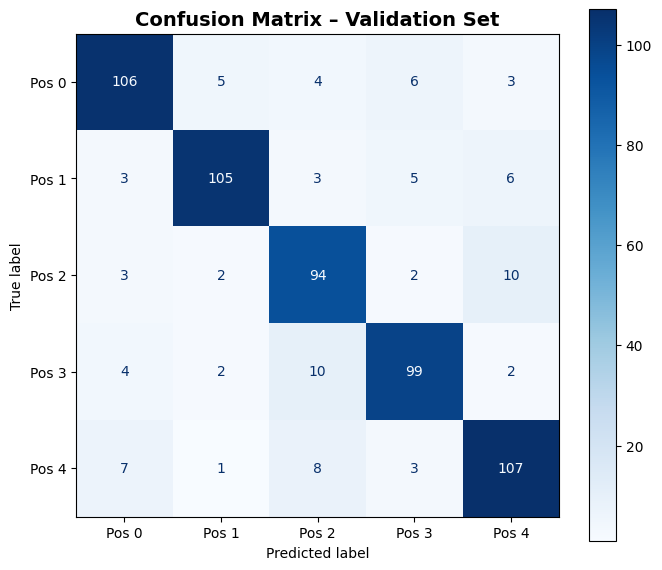


Classification Report (Validation Set):
              precision    recall  f1-score   support

  Position 0       0.86      0.85      0.86       124
  Position 1       0.91      0.86      0.89       122
  Position 2       0.79      0.85      0.82       111
  Position 3       0.86      0.85      0.85       117
  Position 4       0.84      0.85      0.84       126

    accuracy                           0.85       600
   macro avg       0.85      0.85      0.85       600
weighted avg       0.85      0.85      0.85       600



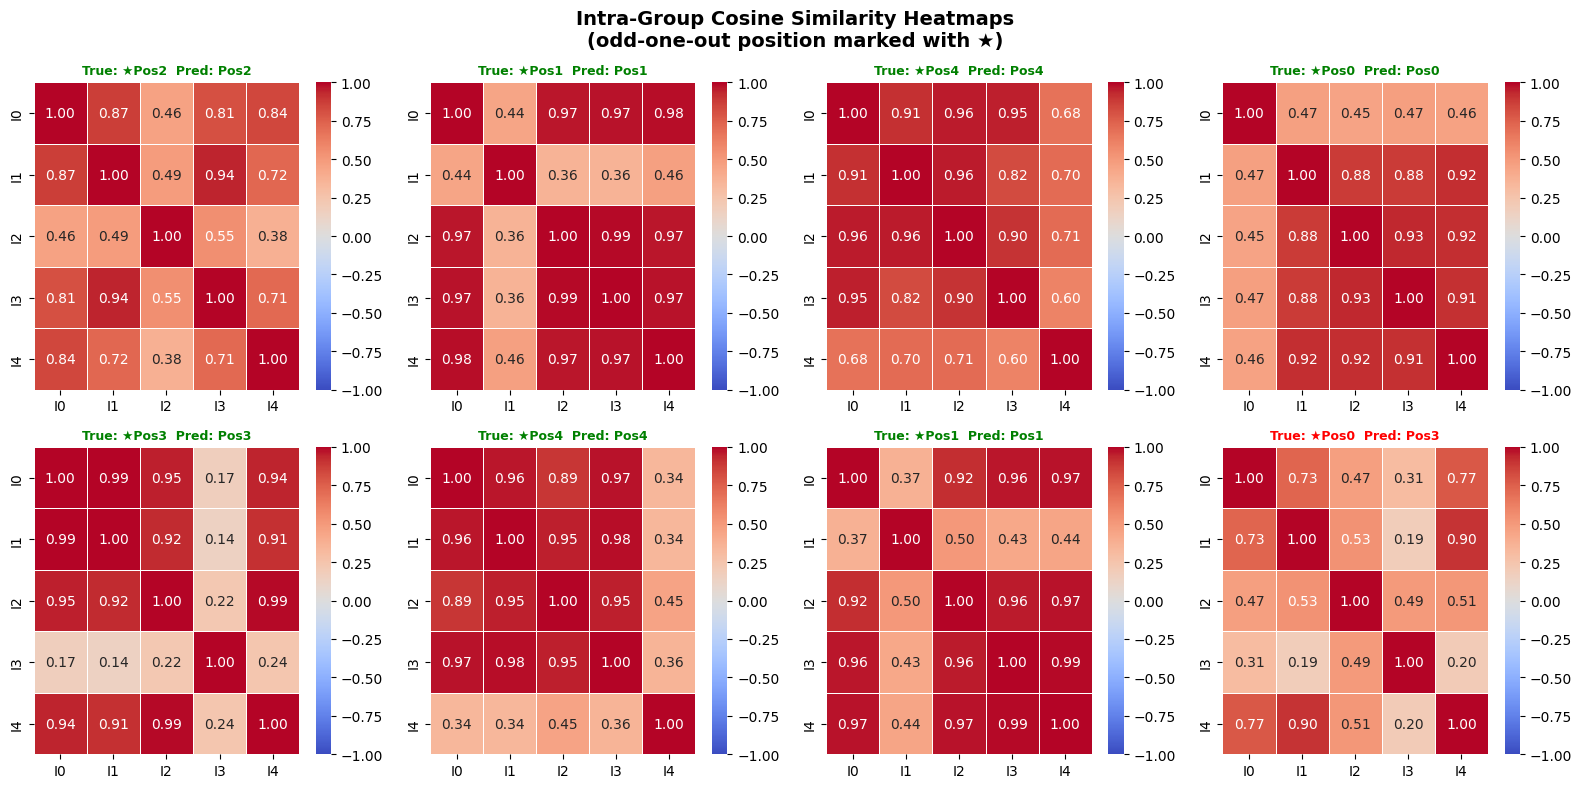

In [18]:
#GRAPHS

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import seaborn as sns

train_losses = []
val_accs     = []
val_losses   = []

# re-initialise model
model_vis = SiameseNetwork().to(device)
opt_vis = optim.Adam(model_vis.parameters(), lr=0.0005, weight_decay=1e-3)
crit_vis = nn.CrossEntropyLoss(label_smoothing=0.15)
sched_vis = torch.optim.lr_scheduler.CosineAnnealingLR(opt_vis, T_max=EPOCHS)
best_val_vis, best_weights_vis = 0.0, None

for epoch in range(EPOCHS):
    model_vis.train()
    epoch_loss = 0.0
    for images, labels in tr_loader:
        images, labels = aug(images, labels)
        images, labels = images.to(device), labels.to(device)
        opt_vis.zero_grad()
        loss = crit_vis(model_vis(images), labels)
        loss.backward()
        opt_vis.step()
        epoch_loss += loss.item()
    sched_vis.step()

    # ── validation ──
    model_vis.eval()
    v_loss, v_correct = 0.0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            out = model_vis(images)
            v_loss += crit_vis(out, labels).item()
            v_correct += (out.argmax(1) == labels).sum().item()

    tl = epoch_loss / len(tr_loader)
    vl = v_loss / len(val_loader)
    va = 100 * v_correct / n_vl
    train_losses.append(tl)
    val_losses.append(vl)
    val_accs.append(va)

    if va > best_val_vis:
        best_val_vis = va
        best_weights_vis = copy.deepcopy(model_vis.state_dict())

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:03d}/{EPOCHS} | Train Loss: {tl:.4f} | Val Loss: {vl:.4f} | Val Acc: {va:.2f}%")

model_vis.load_state_dict(best_weights_vis)
print(f"\nBest Val Accuracy: {best_val_vis:.2f}%")

epochs_range = range(1, EPOCHS + 1)

# Figure 1: Training and Validation Loss + Val Accuracy curves


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Training Curves", fontsize=16, fontweight='bold')

# Loss
axes[0].plot(epochs_range, train_losses, label='Train Loss', color='steelblue', linewidth=1.5)
axes[0].plot(epochs_range, val_losses, label='Val Loss', color='tomato',linewidth=1.5)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].set_title('Loss over Epochs')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(epochs_range, val_accs, label='Val Accuracy', color='seagreen', linewidth=1.5)
axes[1].axhline(y=best_val_vis, color='gold', linestyle='--', linewidth=1.2,
                label=f'Best: {best_val_vis:.2f}%')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy(%)')
axes[1].set_title('Validation Accuracy over Epochs')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# Figure 2: Confusion Matrix (Validation Set)
model_vis.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        preds = model_vis(images).argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=[f'Pos {i}' for i in range(5)])
disp.plot(ax=ax, cmap='Blues', colorbar=True)
ax.set_title('Confusion Matrix – Validation Set', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Per-class metrics
print("\nClassification Report (Validation Set):")
print(classification_report(all_labels, all_preds,
                             target_names=[f'Position {i}' for i in range(5)]))


# Figure 3: Intra-Group Cosine Similarity Heatmaps
model_vis.eval()
sample_images, sample_labels = next(iter(val_loader))
sample_images = sample_images[:8].to(device)
sample_labels = sample_labels[:8]

with torch.no_grad():
    B, N, H, W = sample_images.shape
    flat = sample_images.reshape(-1, 1, H, W)
    feats = model_vis.encoder(flat)
    feats = F.normalize(feats, p=2, dim=1)
    feats = feats.reshape(B, N, -1) # (B, 5, embed_dim)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Intra-Group Cosine Similarity Heatmaps\n(odd-one-out position marked with ★)',
             fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flat):
    sim_matrix = torch.matmul(feats[i], feats[i].T).cpu().numpy()
    sns.heatmap(sim_matrix, ax=ax, cmap='coolwarm', vmin=-1, vmax=1,
                annot=True, fmt='.2f', linewidths=0.5,
                xticklabels=[f'I{j}' for j in range(5)],
                yticklabels=[f'I{j}' for j in range(5)])
    true_pos = sample_labels[i].item()
    pred_pos = (-((feats[i] @ feats[i].T).sum(1) - 1)).argmax().item()
    color = 'green' if pred_pos == true_pos else 'red'
    ax.set_title(f'True: ★Pos{true_pos}  Pred: Pos{pred_pos}',
        fontsize=9, color=color, fontweight='bold')

plt.tight_layout()
plt.savefig('similarity_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()